<a href="https://colab.research.google.com/github/EthanFerba/IDX-Exchange-Data-Science/blob/main/GxBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from itertools import product

rdf = pd.read_csv("Completedf_engineered.csv")

rdf.head()



/tmp/ipykernel_411/1434466474.py:10: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  rdf = pd.read_csv("Completedf_engineered.csv")


,ClosePrice,Latitude,Longitude,PropertyType,LivingArea,CloseDate,ListPrice,DaysOnMarket,ListOfficeName,ListingContractDate,...,OfficialSchoolDistrict_Willows Unified,OfficialSchoolDistrict_Windsor Unified,OfficialSchoolDistrict_Winters Joint Unified,OfficialSchoolDistrict_Wiseburn Unified,OfficialSchoolDistrict_Woodlake Unified,OfficialSchoolDistrict_Woodland Joint Unified,OfficialSchoolDistrict_Yosemite Unified,OfficialSchoolDistrict_Yreka Union High,OfficialSchoolDistrict_Yuba City Unified,OfficialSchoolDistrict_Yucaipa-Calimesa Joint Unified
0,640000.0,34.235979,-117.202269,Residential,2070.0,2022-01-10,565000.0,13.0,Label Realty Group,2021-10-12,...,0,0,0,0,0,0,0,0,0,0
1,438000.0,34.114130,-117.442493,Residential,1174.0,2022-03-23,349999.0,3.0,INTERNATIONAL REAL ESTATE SVCS,2021-10-13,...,0,0,0,0,0,0,0,0,0,0
2,399990.0,39.767729,-121.586400,Residential,1422.0,2022-01-19,399990.0,63.0,"3Tree Realty, Inc.",2021-04-09,...,0,0,0,0,0,0,0,0,0,0
3,1050000.0,34.164901,-118.319259,Residential,1312.0,2022-03-08,1103000.0,33.0,"Ingenious Asset Group, Inc.",2021-10-13,...,0,0,0,0,0,0,0,0,0,0
4,275000.0,34.405539,-116.948065,Residential,1578.0,2022-03-29,272500.0,98.0,Dynasty Real Estate,2021-10-13,...,0,0,0,0,0,0,0,0,0,0


In [4]:

columns_to_drop = [
    "ClosePrice",
    "Log_ClosePrice",
    "CloseDate",
    "PurchaseContractDate",
    "DaysOnMarket",
    "ListingContractDate",
    "ListOfficeName",
    "ListAgentFullName",
    "PropertyType",
    "PropertySubType",
    "ListPrice",
    "Log_ListPrice"
]

columns_to_drop = [
    col for col in columns_to_drop if col in rdf.columns
]


In [5]:

def create_temporal_split(df, training_months_x):

    df = df.copy()
    df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

    max_close_date = df["CloseDate"].max()
    test_start_date = max_close_date.to_period("M").start_time
    test_end_date = test_start_date + pd.DateOffset(months=1)

    train_start_date = test_start_date - pd.DateOffset(
        months=training_months_x
    )

    train_mask = (
        (df["CloseDate"] >= train_start_date)
        & (df["CloseDate"] < test_start_date)
    )

    test_mask = (
        (df["CloseDate"] >= test_start_date)
        & (df["CloseDate"] < test_end_date)
    )

    df_train = df[train_mask].copy()
    df_test = df[test_mask].copy()

    print(f"--- Split Summary for X = {training_months_x} Months ---")
    print(
        f"Train: {train_start_date.date()} to "
        f"{(test_start_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_train)} rows)"
    )
    print(
        f"Test:  {test_start_date.date()} to "
        f"{(test_end_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_test)} rows)"
    )
    print(f"Missing CloseDate rows: {df['CloseDate'].isna().sum()}\n")

    return df_train, df_test


window_options = [3, 6, 12, 24]

for X in window_options:
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=X
    )


--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1



In [6]:

window_options = [3, 6, 12, 24]

depth_options = [3, 5]
learning_rate_options = [0.05, 0.1]
estimators_options = [100, 200]

results = []

for X in window_options:

    train_set, test_set = create_temporal_split(
        rdf, training_months_x=X
    )

    val_start = train_set["CloseDate"].max().to_period("M").start_time

    model_train = train_set[
        train_set["CloseDate"] < val_start
    ].copy()

    val_set = train_set[
        train_set["CloseDate"] >= val_start
    ].copy()

    X_train = model_train.drop(columns=columns_to_drop)
    y_train = model_train["ClosePrice"]

    X_val = val_set.drop(columns=columns_to_drop)
    y_val = val_set["ClosePrice"]

    X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
    X_val = X_val.loc[:, ~X_val.columns.duplicated()].copy()

    X_train = pd.get_dummies(X_train, dtype="int8")
    X_val = pd.get_dummies(X_val, dtype="int8")

    X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
    X_val = X_val.loc[:, ~X_val.columns.duplicated()].copy()

    X_val = X_val.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_val = X_val.replace([np.inf, -np.inf], np.nan)

    for depth, lr, estimators in product(
        depth_options,
        learning_rate_options,
        estimators_options
    ):

        model = XGBRegressor(
            max_depth=depth,
            learning_rate=lr,
            n_estimators=estimators,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        r2 = r2_score(y_val, predictions)
        mae = mean_absolute_error(y_val, predictions)


        results.append({
            "Training_Months": X,
            "Max_Depth": depth,
            "Learning_Rate": lr,
            "N_Estimators": estimators,
            "R2": r2,
            "MAE": mae
        })

results_df = pd.DataFrame(results)

# Sort
results_df = results_df.sort_values(
    by="R2",
    ascending=False
)

display(results_df)


--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1



,Training_Months,Max_Depth,Learning_Rate,N_Estimators,R2,MAE
27,24,3,0.10,200,0.762401,250211.286637
31,24,5,0.10,200,0.760893,220548.990605
29,24,5,0.05,200,0.755987,235772.497761
30,24,5,0.10,100,0.755866,236153.526977
11,6,3,0.10,200,0.753833,248862.008794
7,3,5,0.10,200,0.749572,225558.156345
13,6,5,0.05,200,0.749129,233865.739790
15,6,5,0.10,200,0.747565,221250.758465
26,24,3,0.10,100,0.743170,270926.630311
28,24,5,0.05,100,0.742129,254734.817778


In [7]:

best = results_df.iloc[0]

best_window = int(best["Training_Months"])
best_depth = int(best["Max_Depth"])
best_lr = float(best["Learning_Rate"])
best_estimators = int(best["N_Estimators"])

print("Best Training Window:", best_window)
print("Best Max Depth:", best_depth)
print("Best Learning Rate:", best_lr)
print("Best N Estimators:", best_estimators)
print("Validation R2:", round(best["R2"], 4))
print("Validation MAE:", round(best["MAE"], 2))


Best Training Window: 24
Best Max Depth: 3
Best Learning Rate: 0.1
Best N Estimators: 200
Validation R2: 0.7624
Validation MAE: 250211.29


In [8]:


train_set, test_set = create_temporal_split(
    rdf, training_months_x=best_window
)


X_train = train_set.drop(columns=columns_to_drop)
y_train = train_set["ClosePrice"]

X_test = test_set.drop(columns=columns_to_drop)
y_test = test_set["ClosePrice"]

X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

X_train = pd.get_dummies(X_train, dtype="int8")
X_test = pd.get_dummies(X_test, dtype="int8")

X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Duplicate training columns:", X_train.columns.duplicated().sum())
print("Duplicate testing columns:", X_test.columns.duplicated().sum())

best_model = XGBRegressor(
    max_depth=best_depth,
    learning_rate=best_lr,
    n_estimators=best_estimators,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train
best_model.fit(X_train, y_train)

# predictions
predictions = best_model.predict(X_test)

# Evaluate
test_r2 = r2_score(y_test, predictions)


print("\nFinal XGBoost Test Results")
print("R2:", round(test_r2, 4))



--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (3238 rows)
Missing CloseDate rows: 1

Duplicate training columns: 0
Duplicate testing columns: 0

Final XGBoost Test Results
R2: 0.791


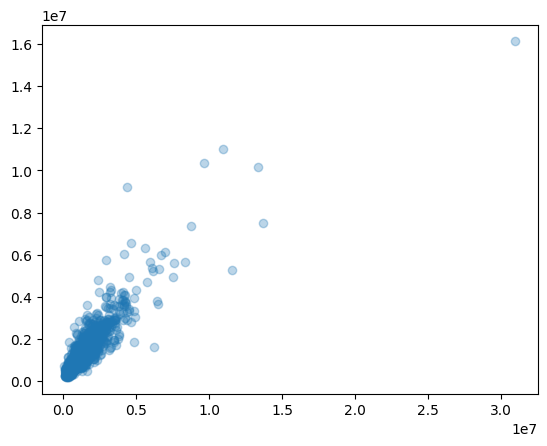

In [9]:
plt.scatter(y_test, predictions, alpha=0.3)

In [10]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Prepare target variables (Standard vs Log-transformed)
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# 2. Retrain using Log Target
best_model_log = XGBRegressor(
    max_depth=best_depth,
    learning_rate=best_lr,
    n_estimators=best_estimators,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

best_model_log.fit(X_train, y_train_log)

# 3. Predict on log scale and transform back
predictions_log_scale = best_model_log.predict(X_test)
predictions_backtransformed = np.expm1(predictions_log_scale)

# 4. Compare performance metrics on the original scale
test_r2_standard = r2_score(y_test, predictions)
test_mae_standard = mean_absolute_error(y_test, predictions)

test_r2_log = r2_score(y_test, predictions_backtransformed)
test_mae_log = mean_absolute_error(y_test, predictions_backtransformed)

print("=== Performance Comparison on Original scale ===")
print(f"Standard Target model -> R2: {test_r2_standard:.4f} | MAE: {test_mae_standard:.2f}")
print(f"Log Target model      -> R2: {test_r2_log:.4f} | MAE: {test_mae_log:.2f}")

=== Performance Comparison on Original scale ===
Standard Target model -> R2: 0.7910 | MAE: 223526.71
Log Target model      -> R2: 0.7320 | MAE: 198040.98


In [11]:
# Train a more robust, deeper XGBoost model to boost original R^2
optimized_model = XGBRegressor(
    max_depth=6,
    learning_rate=0.05,
    n_estimators=500,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Fit the model on the full 24-month training data
print("Training optimized model...")
optimized_model.fit(X_train, y_train)

# Evaluate predictions
opt_predictions = optimized_model.predict(X_test)
opt_test_r2 = r2_score(y_test, opt_predictions)
opt_test_mae = mean_absolute_error(y_test, opt_predictions)

print("=== Optimized Model Test Results ===")
print(f"Optimized Model R2:  {opt_test_r2:.4f}  (Previous: {test_r2_standard:.4f})")
print(f"Optimized Model MAE: {opt_test_mae:.2f} (Previous: {test_mae_standard:.2f})")

Training optimized model...
=== Optimized Model Test Results ===
Optimized Model R2:  0.8189  (Previous: 0.7910)
Optimized Model MAE: 174059.81 (Previous: 223526.71)


In [12]:
def calculate_mape_mdape(y_true, y_pred):
    # Avoid division by zero by filtering out actual zeros if they exist
    mask = y_true != 0
    y_true_filtered = y_true[mask]
    y_pred_filtered = y_pred[mask]

    percentage_errors = np.abs((y_true_filtered - y_pred_filtered) / y_true_filtered) * 100
    mape = np.mean(percentage_errors)
    mdape = np.median(percentage_errors)
    return mape, mdape

# Calculate for standard model
std_mape, std_mdape = calculate_mape_mdape(y_test.values, predictions)

# Calculate for optimized model
opt_mape, opt_mdape = calculate_mape_mdape(y_test.values, opt_predictions)

print("=== Percentage Error Metrics (MAPE & MdAPE) ===")
print(f"Standard Model   -> MAPE: {std_mape:.2f}% | MdAPE: {std_mdape:.2f}%")
print(f"Optimized Model  -> MAPE: {opt_mape:.2f}% | MdAPE: {opt_mdape:.2f}%")

=== Percentage Error Metrics (MAPE & MdAPE) ===
Standard Model   -> MAPE: 23.55% | MdAPE: 15.68%
Optimized Model  -> MAPE: 16.96% | MdAPE: 11.49%
